In [ ]:

!pip install -q datasets pandas pillow matplotlib

In [ ]:

from datasets import load_dataset

print("Downloading ACNE04 dataset...")

dataset = load_dataset("Layered-Labs/ACNE04")

print("Download completed!")
print(dataset)

data = dataset["train"]

print("Total images:", len(data))
print("Columns:", data.column_names)


Download completed!
DatasetDict({
    train: Dataset({
        features: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split'],
        num_rows: 1457
    })
})
Total images: 1457
Columns: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split']


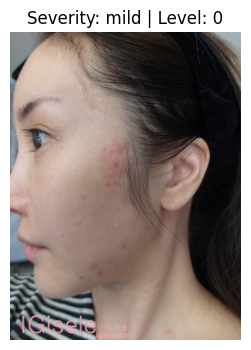

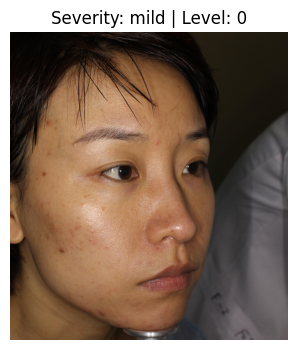

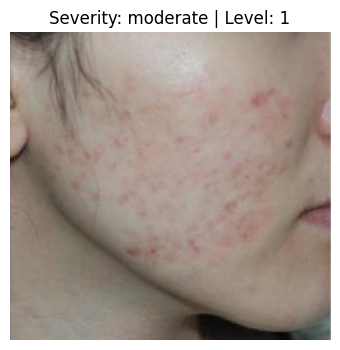

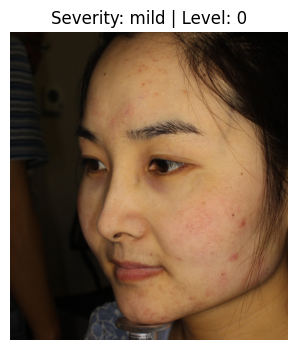

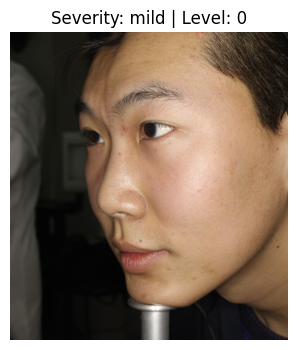

In [ ]:

import matplotlib.pyplot as plt

for i in range(5):
    sample = data[i]

    plt.figure(figsize=(5, 4))
    plt.imshow(sample["image"])
    plt.title(
        f"Severity: {sample['severity']} | "
        f"Level: {sample['level']}"
    )
    plt.axis("off")
    plt.show()


In [ ]:

import os
import json
import pandas as pd

output_dir = "/content/drive/MyDrive/SkinCare_AI/ACNE04"
image_dir = os.path.join(output_dir, "images")

os.makedirs(image_dir, exist_ok=True)

records = []

for i, sample in enumerate(data):
    filename = sample["file_name"]

    image_path = os.path.join(image_dir, filename)
    sample["image"].save(image_path)

    records.append({
        "filename": filename,
        "severity": sample["severity"],
        "level": sample["level"],
        "lesion_count": sample["num_lesions_annotated"],
        "lesion_boxes": json.dumps(sample["lesion_boxes"]),
        "split": sample["split"],
        "image_path": image_path
    })

df = pd.DataFrame(records)

df.to_csv(
    os.path.join(output_dir, "annotations.csv"),
    index=False
)

print("Images saved:", len(df))
print("Annotations saved successfully!")
print("Dataset location:", output_dir)


Images saved: 1457
Annotations saved successfully!
Dataset location: /content/drive/MyDrive/SkinCare_AI/ACNE04


In [ ]:
import pandas as pd

annotations_path = "/content/drive/MyDrive/SkinCare_AI/ACNE04/annotations.csv"

df = pd.read_csv(annotations_path)

print("Total records:", len(df))
print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Total records: 1457

Dataset columns:
['filename', 'severity', 'level', 'lesion_count', 'lesion_boxes', 'split', 'image_path']

First 5 records:


,filename,severity,level,lesion_count,lesion_boxes,split,image_path
0,levle0_0.jpg,mild,0,3,"{""xmin"": [223, 217, 186], ""ymin"": [290, 250, 5...",train,/content/drive/MyDrive/SkinCare_AI/ACNE04/imag...
1,levle0_1.jpg,mild,0,3,"{""xmin"": [394, 654, 930], ""ymin"": [933, 2160, ...",train,/content/drive/MyDrive/SkinCare_AI/ACNE04/imag...
2,levle0_10.jpg,moderate,1,20,"{""xmin"": [357, 394, 314, 316, 265, 170, 203, 9...",train,/content/drive/MyDrive/SkinCare_AI/ACNE04/imag...
3,levle0_100.jpg,mild,0,2,"{""xmin"": [2570, 2455], ""ymin"": [2075, 2451], ""...",train,/content/drive/MyDrive/SkinCare_AI/ACNE04/imag...
4,levle0_101.jpg,mild,0,1,"{""xmin"": [1175], ""ymin"": [1002], ""xmax"": [1413...",train,/content/drive/MyDrive/SkinCare_AI/ACNE04/imag...



Missing values:
filename        0
severity        0
level           0
lesion_count    0
lesion_boxes    0
split           0
image_path      0
dtype: int64


In [ ]:
from PIL import Image
import os

image_dir = "/content/drive/MyDrive/SkinCare_AI/ACNE04/images"

valid = 0
invalid = 0

for filename in os.listdir(image_dir):
    path = os.path.join(image_dir, filename)

    try:
        with Image.open(path) as img:
            img.verify()
        valid += 1

    except Exception:
        invalid += 1

print("Valid images:", valid)
print("Invalid images:", invalid)

Valid images: 1457
Invalid images: 0


Severity distribution:
severity
mild           513
moderate       633
severe         182
very_severe    129
Name: count, dtype: int64


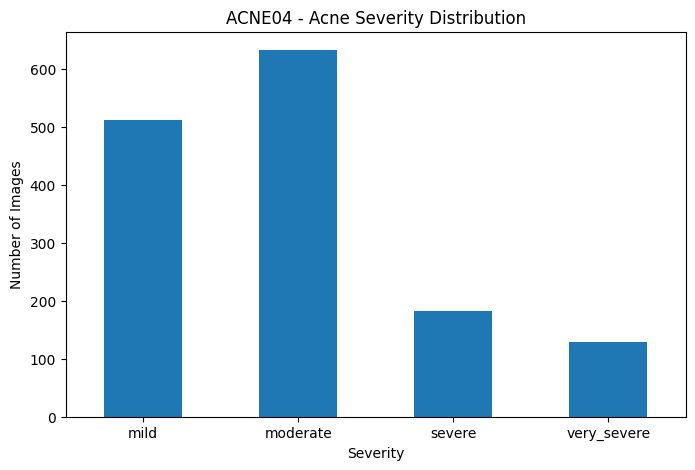

In [ ]:
import matplotlib.pyplot as plt

severity_counts = df["severity"].value_counts().sort_index()

print("Severity distribution:")
print(severity_counts)

plt.figure(figsize=(8, 5))
severity_counts.plot(kind="bar")

plt.title("ACNE04 - Acne Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

In [ ]:
print("Original dataset split:")
print(df["split"].value_counts())

print("\nSeverity labels:")
print(df["severity"].value_counts())

Original dataset split:
split
train    1165
test      292
Name: count, dtype: int64

Severity labels:
severity
moderate       633
mild           513
severe         182
very_severe    129
Name: count, dtype: int64


In [ ]:

import pandas as pd
import os
from sklearn.model_selection import train_test_split

# Load annotations
annotations_path = "/content/drive/MyDrive/SkinCare_AI/ACNE04/annotations.csv"
df = pd.read_csv(annotations_path)

# Create output folder
split_dir = "/content/drive/MyDrive/SkinCare_AI/ACNE04/splits"
os.makedirs(split_dir, exist_ok=True)

# Preserve the original test split
train_val = df[df["split"] == "train"].copy()
test_data = df[df["split"] == "test"].copy()

# Divide original training data into train and validation
train_data, val_data = train_test_split(
    train_val,
    test_size=0.1765,
    random_state=42,
    stratify=train_val["severity"]
)

# Save CSV files
train_data.to_csv(
    os.path.join(split_dir, "train.csv"), index=False
)

val_data.to_csv(
    os.path.join(split_dir, "validation.csv"), index=False
)

test_data.to_csv(
    os.path.join(split_dir, "test.csv"), index=False
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))
print("Total:", len(train_data) + len(val_data) + len(test_data))


Training images: 959
Validation images: 206
Testing images: 292
Total: 1457


In [ ]:

print("TRAINING SET")
print(train_data["severity"].value_counts())

print("\nVALIDATION SET")
print(val_data["severity"].value_counts())

print("\nTESTING SET")
print(test_data["severity"].value_counts())


TRAINING SET
severity
moderate       417
mild           337
severe         120
very_severe     85
Name: count, dtype: int64

VALIDATION SET
severity
moderate       89
mild           73
severe         26
very_severe    18
Name: count, dtype: int64

TESTING SET
severity
moderate       127
mild           103
severe          36
very_severe     26
Name: count, dtype: int64


In [ ]:
import json
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/SkinCare_AI/ACNE04/annotations.csv"
)

print("ANNOTATION VERIFICATION")
print("-" * 50)

for index, row in df.iterrows():

    boxes = json.loads(row["lesion_boxes"])

    xmin_count = len(boxes["xmin"])
    ymin_count = len(boxes["ymin"])
    xmax_count = len(boxes["xmax"])
    ymax_count = len(boxes["ymax"])

    stored_count = row["lesion_count"]

    coordinates_match = (
        xmin_count == ymin_count == xmax_count == ymax_count
    )

    if not coordinates_match or xmin_count != stored_count:
        print("\nImage:", row["filename"])
        print("Stored lesion count:", stored_count)
        print("Bounding boxes:", xmin_count)
        print("Coordinate arrays consistent:", coordinates_match)

print("\nAnnotation verification completed.")



ANNOTATION VERIFICATION
--------------------------------------------------

Annotation verification completed.


In [ ]:

from PIL import Image

image_path = df.iloc[0]["image_path"]

img = Image.open(image_path)

print("Image width:", img.width)
print("Image height:", img.height)
print("Image size:", img.size)


Image width: 525
Image height: 700
Image size: (525, 700)


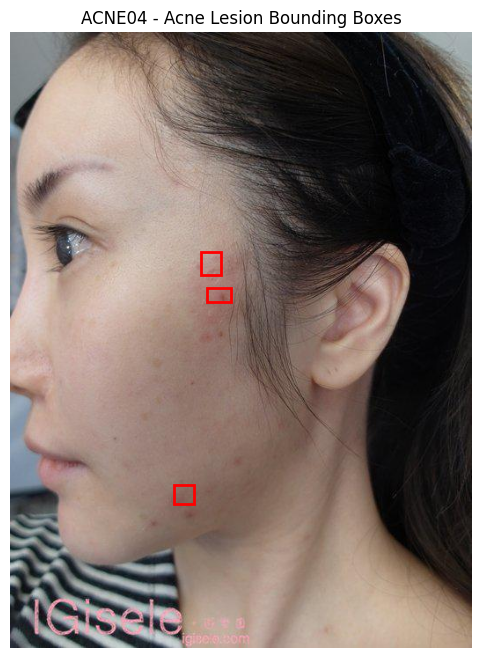

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import json

row = df.iloc[0]

image = Image.open(row["image_path"]).convert("RGB")
boxes = json.loads(row["lesion_boxes"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image)

for i in range(len(boxes["xmin"])):
    xmin = boxes["xmin"][i]
    ymin = boxes["ymin"][i]
    xmax = boxes["xmax"][i]
    ymax = boxes["ymax"][i]

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title("ACNE04 - Acne Lesion Bounding Boxes")
ax.axis("off")
plt.show()

In [ ]:
!pip install -q --upgrade ipympl

In [ ]:
%matplotlib inline

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import json

print("Matplotlib version:", matplotlib.__version__)
print("Current backend:", matplotlib.get_backend())
print("Plotting setup completed!")

Matplotlib version: 3.10.0
Current backend: module://matplotlib_inline.backend_inline
Plotting setup completed!


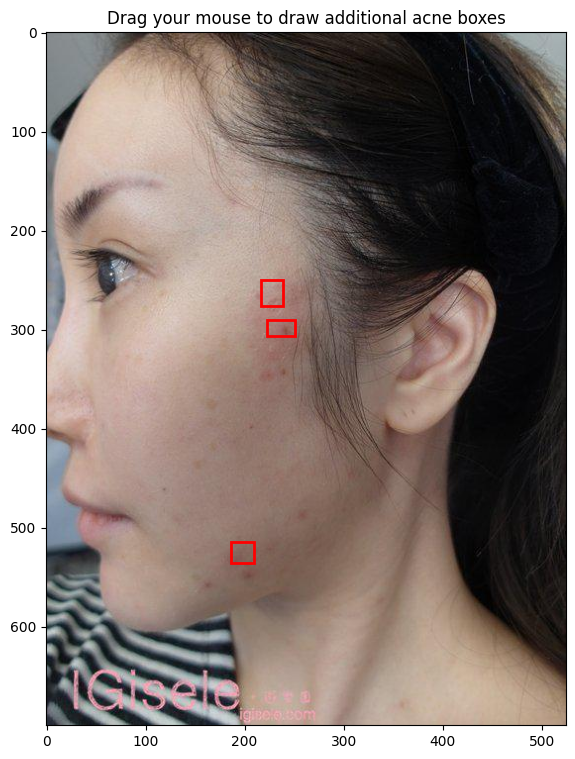

Button(button_style='success', description='Finish Annotation', style=ButtonStyle())

In [ ]:
import ipywidgets as widgets
from IPython.display import display
from matplotlib.widgets import RectangleSelector
from PIL import Image

# Select the image to annotate
image_index = 0

row = df.iloc[image_index]
image = Image.open(row["image_path"]).convert("RGB")

# Load existing annotations
boxes = json.loads(row["lesion_boxes"])

# Store additional boxes
new_boxes = []

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(image)
ax.set_title("Drag your mouse to draw additional acne boxes")

# Display existing boxes in red
for i in range(len(boxes["xmin"])):
    ax.add_patch(
        patches.Rectangle(
            (boxes["xmin"][i], boxes["ymin"][i]),
            boxes["xmax"][i] - boxes["xmin"][i],
            boxes["ymax"][i] - boxes["ymin"][i],
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )
    )

# Function to draw new boxes
def on_select(eclick, erelease):

    if eclick.xdata is None or erelease.xdata is None:
        return

    xmin = int(min(eclick.xdata, erelease.xdata))
    ymin = int(min(eclick.ydata, erelease.ydata))
    xmax = int(max(eclick.xdata, erelease.xdata))
    ymax = int(max(eclick.ydata, erelease.ydata))

    width, height = image.size

    xmin = max(0, min(xmin, width))
    xmax = max(0, min(xmax, width))
    ymin = max(0, min(ymin, height))
    ymax = max(0, min(ymax, height))

    if xmax <= xmin or ymax <= ymin:
        return

    new_boxes.append({
        "xmin": xmin,
        "ymin": ymin,
        "xmax": xmax,
        "ymax": ymax
    })

    ax.add_patch(
        patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
    )

    fig.canvas.draw_idle()

# Activate rectangle drawing
selector = RectangleSelector(
    ax,
    on_select,
    useblit=False,
    button=[1],
    minspanx=3,
    minspany=3,
    spancoords="pixels",
    interactive=False
)

plt.show()

# Finish button
finish_button = widgets.Button(
    description="Finish Annotation",
    button_style="success"
)

def finish_annotation(button):
    selector.set_active(False)

    print("\nNew bounding boxes added:", len(new_boxes))

    for i, box in enumerate(new_boxes):
        print(f"Box {i+1}: {box}")

finish_button.on_click(finish_annotation)

display(finish_button)